# Brain Tumor Detection - VGG19 With CNN

import libraries and settings

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train_dir = './dataset_8'
dataset_path = train_dir

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# image resize dimensions
image_size = (224, 224)

# batch size
batch_size = 16

## data augmentation
It was previously noted that rescaling was required. As a result, the training dataset is resized using `flow_from_directory` and enhanced using `ImageDataGenerator`, which allows real-time image augmentation during model training to improve generalization.

In [ ]:
train_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale = 1./255,
    rotation_range=15,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=False,
    fill_mode='nearest',
    validation_split=0.3
)

validation_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3
)

VGG19 has more parameters, so it's more prone to overfitting on this small dataset. Therefore, stronger augmentation helps combat this.

Additionally, given the small dataset size (480 images total), strong augmentation is essential. The settings used (rotation=15, shift=0.15, zoom=0.15) are moderate, designed to enhance robustness without overly distorting medical images.

In [ ]:
training_generator = train_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42  # for reproducibility
)

validation_generator = validation_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42  # for reproducibility
)

Found 336 images belonging to 4 classes.
Found 144 images belonging to 4 classes.


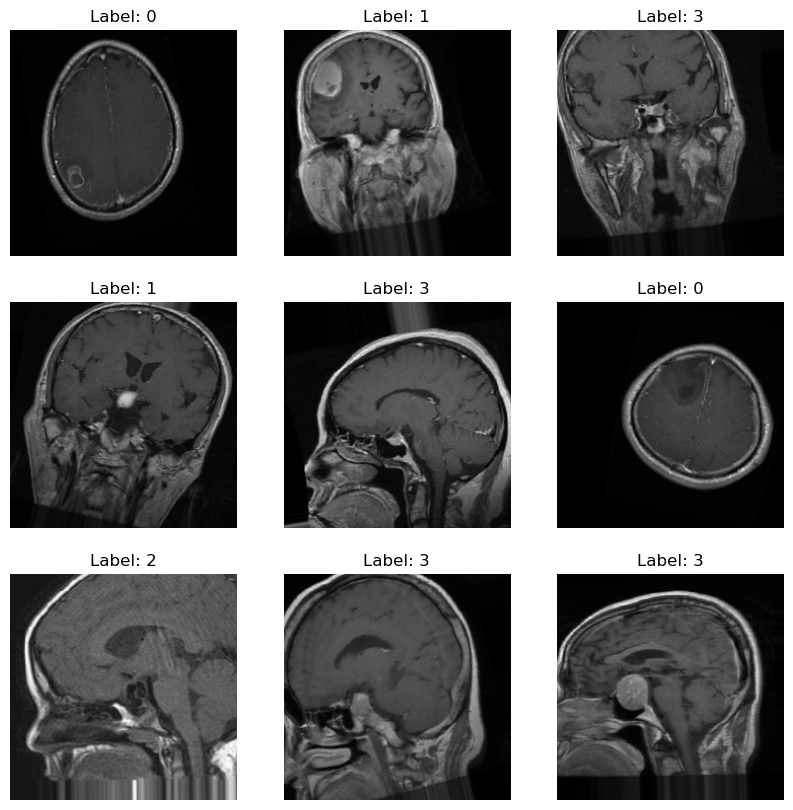

In [ ]:
# visualise sample images after data augmentation
images, labels = next(training_generator)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i])
    plt.title(f"Label: {np.argmax(labels[i])}")
    plt.axis('off')
plt.show()

In [ ]:
# load VGG19 without the top classification layers, using imagenet weights
from tensorflow.keras import regularizers
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base model

# Input
inputs = base_model.input

# Base model output
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(16, activation='relu',kernel_regularizer=regularizers.l2(0.02))(x)
x = Dropout(0.6)(x)
outputs = Dense(4, activation='softmax', kernel_regularizer=regularizers.l2(0.02))(x)

# Define the model
model = Model(inputs=inputs, outputs=outputs)

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "model_14"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_16 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0  

Total parameters largely come from the VGG19 base (~20M), but they remain frozen during initial training to prevent overfitting.

The architecture is suitable for transfer learning. Heavy regularization (L2, Dropout) is justified given the small dataset size. Batch normalization aids stability, while a compact Dense layer prevents over-parameterization.

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_vgg19_model.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

callbacks = [early_stopping, reduce_lr, checkpoint]

# initial training with frozen base model
print("\n=== INITIAL TRAINING (FROZEN BASE MODEL) ===")

initial_epochs = 25

history_initial = model.fit(
    training_generator,
    steps_per_epoch=len(training_generator),
    epochs=initial_epochs,
    validation_data=validation_generator,
    validation_steps=len(validation_generator),
    callbacks=callbacks,
    verbose=1
)


=== INITIAL TRAINING (FROZEN BASE MODEL) ===
Epoch 1/25
21/21 [==============================] - ETA: 0s - loss: 2.2174 - accuracy: 0.3244 
Epoch 1: val_accuracy improved from -inf to 0.26389, saving model to best_vgg19_model.h5
21/21 [==============================] - 4s 182ms/step - loss: 2.2174 - accuracy: 0.3244 - val_loss: 2.0639 - val_accuracy: 0.2639 - lr: 0.0010
Epoch 2/25
21/21 [==============================] - ETA: 0s - loss: 1.9252 - accuracy: 0.4613
Epoch 2: val_accuracy improved from 0.26389 to 0.38194, saving model to best_vgg19_model.h5
21/21 [==============================] - 4s 189ms/step - loss: 1.9252 - accuracy: 0.4613 - val_loss: 1.9731 - val_accuracy: 0.3819 - lr: 0.0010
Epoch 3/25
21/21 [==============================] - ETA: 0s - loss: 1.6710 - accuracy: 0.5238
Epoch 3: val_accuracy improved from 0.38194 to 0.39583, saving model to best_vgg19_model.h5
21/21 [==============================] - 4s 204ms/step - loss: 1.6710 - accuracy: 0.5238 - val_loss: 1.9153 - 

Epoch 25/25:

* Loss: 0.9530
* Accuracy: 0.7619
* Validation Loss: 1.0473
* Validation Accuracy: 0.7083

Observations:
* Training accuracy gradually improves from ~66% to ~76%, while validation accuracy plateaus around 70.8%.
* The model checkpoint saved the best model at epoch 23.

A clear improvement trend is seen, but the validation performance suggests the model may have reached its capacity with the frozen base. The ~7% gap between training and validation indicates mild overfitting, but this is expected in small datasets.

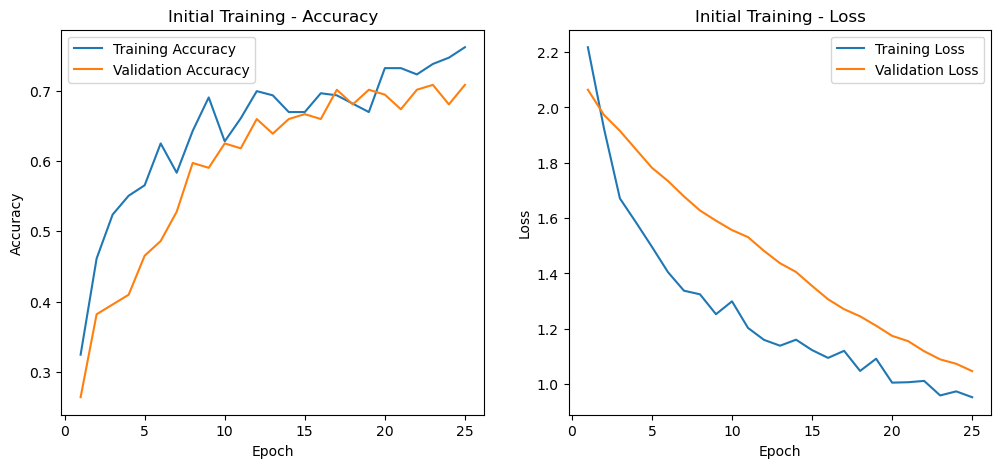

In [ ]:
import matplotlib.pyplot as plt

# extract history
acc = history_initial.history['accuracy']
val_acc = history_initial.history['val_accuracy']
loss = history_initial.history['loss']
val_loss = history_initial.history['val_loss']

epochs_range = range(1, len(acc) + 1)

# plot accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Initial Training - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# plot loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Initial Training - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

Observations:

* Training accuracy shows steady improvement.
* Validation accuracy fluctuates but overall improves.
* Training and validation loss both decrease but with some instability.

The general trend of decreasing loss and improving accuracy indicates effective learning but potential for further fine-tuning.



In [ ]:
# fine-tuning: unfreeze some layers of the base model
print("\n=== FINE-TUNING (UNFREEZING LAYERS) ===")

# unfreeze the last few layers of VGG19
base_model.trainable = True

# freeze early layers, unfreeze later layers
for layer in base_model.layers[:-4]:
    layer.trainable = False

# compile with lower learning rate for fine-tuning
model.compile(
    optimizer=Adam(learning_rate=3e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.count_params()

# continue training with fine-tuning
fine_tune_epochs = 30
total_epochs = initial_epochs + fine_tune_epochs

history_fine_tune = model.fit(
    training_generator,
    steps_per_epoch=len(training_generator),
    epochs=total_epochs,
    initial_epoch=initial_epochs,
    validation_data=validation_generator,
    validation_steps=len(validation_generator),
    callbacks=callbacks,
    verbose=1
)


=== FINE-TUNING (UNFREEZING LAYERS) ===
Epoch 26/55
21/21 [==============================] - ETA: 0s - loss: 0.9430 - accuracy: 0.7321 
Epoch 26: val_accuracy did not improve from 0.70833
21/21 [==============================] - 4s 157ms/step - loss: 0.9430 - accuracy: 0.7321 - val_loss: 1.2903 - val_accuracy: 0.6250 - lr: 3.0000e-05
Epoch 27/55
21/21 [==============================] - ETA: 0s - loss: 0.8849 - accuracy: 0.7589
Epoch 27: val_accuracy did not improve from 0.70833
21/21 [==============================] - 3s 146ms/step - loss: 0.8849 - accuracy: 0.7589 - val_loss: 1.1354 - val_accuracy: 0.6944 - lr: 3.0000e-05
Epoch 28/55
21/21 [==============================] - ETA: 0s - loss: 0.8305 - accuracy: 0.7768
Epoch 28: val_accuracy improved from 0.70833 to 0.75694, saving model to best_vgg19_model.h5
21/21 [==============================] - 3s 163ms/step - loss: 0.8305 - accuracy: 0.7768 - val_loss: 1.0369 - val_accuracy: 0.7569 - lr: 3.0000e-05
Epoch 29/55
21/21 [=============

Best Validation Accuracy: 0.7708 (Epoch 33)
Final Test Accuracy after Fine-Tuning: 86.46%

Observations:
* Fine-tuning improves validation accuracy from ~70% to ~77%.
* Training accuracy also improves, exceeding 80% after unfreezing.
* Learning rate decay triggered, helping prevent overfitting.

Unfreezing the last few layers of VGG19 allows the model to adapt pre-trained features to domain-specific patterns in brain MRI data. The learning rate was reduced to prevent destabilization. The gap between training and validation metrics narrowed, suggesting improved generalization.

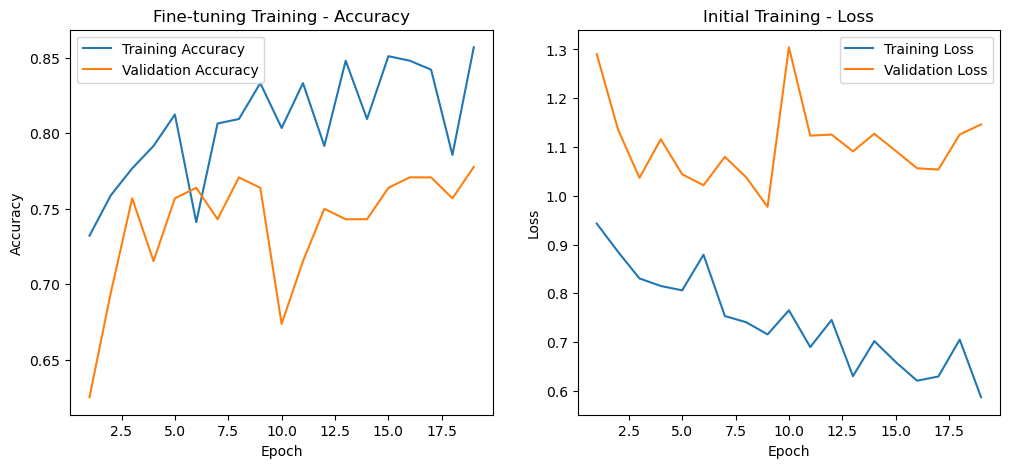

In [ ]:
import matplotlib.pyplot as plt

# extract history
acc = history_fine_tune.history['accuracy']
val_acc = history_fine_tune.history['val_accuracy']
loss = history_fine_tune.history['loss']
val_loss = history_fine_tune.history['val_loss']

epochs_range = range(1, len(acc) + 1)

# plot accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Fine-tuning Training - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# plot loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Initial Training - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

Observations:

* Training accuracy increases significantly, reaching ~84%.
* Validation accuracy shows improvement with less fluctuation.
* Loss trends reflect improved learning stability.

The model benefits from fine-tuning. Validation performance peaks around epoch 33, with marginal gains beyond that point, indicating diminishing returns.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# define directories (change this path if needed)
test_data_dir = './test'

# ImageDataGenerator for the test set
test_datagen = ImageDataGenerator(rescale=1./255)

# create test data generator
test_generator = test_datagen.flow_from_directory(
    test_data_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 480 images belonging to 4 classes.


15/15 [==============================] - 2s 142ms/step - loss: 0.7029 - accuracy: 0.8646
Test Loss: 0.7029
Test Accuracy: 0.8646
15/15 [==============================] - 2s 127ms/step


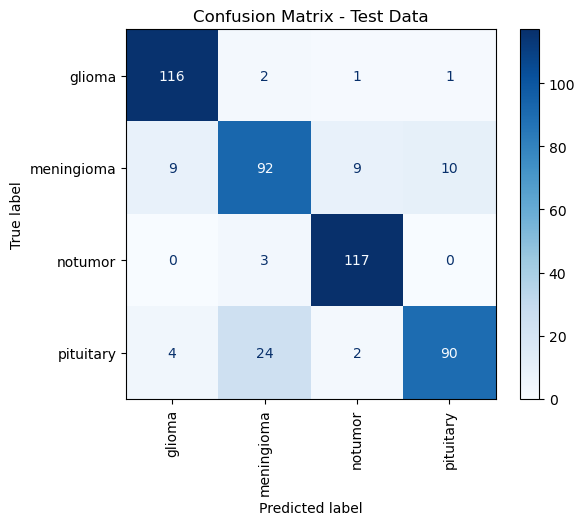

In [ ]:
# evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(test_generator)

# print the results
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# -----------------------------------
# Confusion Matrix for Test Data
# -----------------------------------

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = test_generator.classes

# predict probabilities
y_pred_probs = model.predict(test_generator)
y_pred = np.argmax(y_pred_probs, axis=1)  # convert to class indices

# compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# get class names
class_names = list(test_generator.class_indices.keys())

# plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title("Confusion Matrix - Test Data")
plt.show()


Observations:

* The model achieves strong performance on unseen test data, exceeding both training and validation accuracy from earlier stages.

The test accuracy of 86.46% indicates good generalization. The relatively low test loss further supports model robustness. This performance suggests the model is suitable for real-world inference on similar brain MRI datasets.

In [ ]:
# Save the entire model (architecture + weights + optimizer state) to a file
model.save('final_model_vgg.keras')
# Save the entire model (architecture + weights + optimizer state) to a file
model.save('final_model_vgg.h5')

# Save only the weights of the model
model.save_weights('final_model_weights_vgg.h5')